# Государственный бюджет Армении: примеры запросов

Примеры работы с базой `data/arm_budget.duckdb` (данные «Интерактивного бюджета» Минфина Армении,
<https://budget.minfin.am:82/>). Суммы — в тысячах драмов (`_kamd`), нарастающим итогом с 1 января.
Описание базы: [docs/ru/database.md](ru/database.md), словарь данных: [docs/data_dictionary.md](data_dictionary.md).

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
con = duckdb.connect(str(ROOT / "data" / "arm_budget.duckdb"), read_only=True)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)


def q(sql: str, **params) -> pd.DataFrame:
    return con.execute(sql, params).df()


q("SELECT * FROM meta_year ORDER BY year")

,year,year_index,as_of_date,is_complete
0,2024,3,2024-12-31,True
1,2025,2,2025-12-30,True
2,2026,1,2026-11-04,False


## Итоги по годам

План и исполнение расходов, доходов и дефицита, млрд драмов. Последний год — неполный (`as_of_date`).

In [2]:
q("""
SELECT year, as_of_date,
       round(expenditure_plan_kamd / 1e6, 1) AS exp_plan_bn, round(expenditure_actual_kamd / 1e6, 1) AS exp_actual_bn,
       round(revenue_plan_kamd / 1e6, 1) AS rev_plan_bn, round(revenue_actual_kamd / 1e6, 1) AS rev_actual_bn,
       round(deficit_plan_kamd / 1e6, 1) AS deficit_plan_bn, expenditure_lines, revenue_lines, contracts
FROM v_summary ORDER BY year""")

,year,as_of_date,exp_plan_bn,exp_actual_bn,rev_plan_bn,rev_actual_bn,deficit_plan_bn,expenditure_lines,revenue_lines,contracts
0,2024,2024-12-31,3148.7,2975.0,2679.5,2573.5,456.0,3752,454,26320
1,2025,2025-12-30,3459.8,3319.1,2844.6,2873.0,409.9,3621,468,26736
2,2026,2026-11-04,3752.2,2899.2,3204.2,2701.2,548.1,3613,479,22739


## Расходы по функциональной классификации (COFOG)

Названия разделов — на русском (`func_section_ru`).

year,2024,2025,2026
func_section_ru,,,
Общегосударственные услуги,671.8,739.7,697.4
Оборона,549.0,678.9,390.5
"Общественный порядок, безопасность и судебная деятельность",229.3,247.1,203.8
Экономические отношения,219.9,222.4,156.9
Охрана окружающей среды,10.8,14.3,21.3
Жилищное строительство и коммунальные услуги,14.5,11.8,8.1
Здравоохранение,154.9,165.8,249.9
"Отдых, культура и религия",40.9,43.1,39.3
Образование,231.3,320.0,275.7


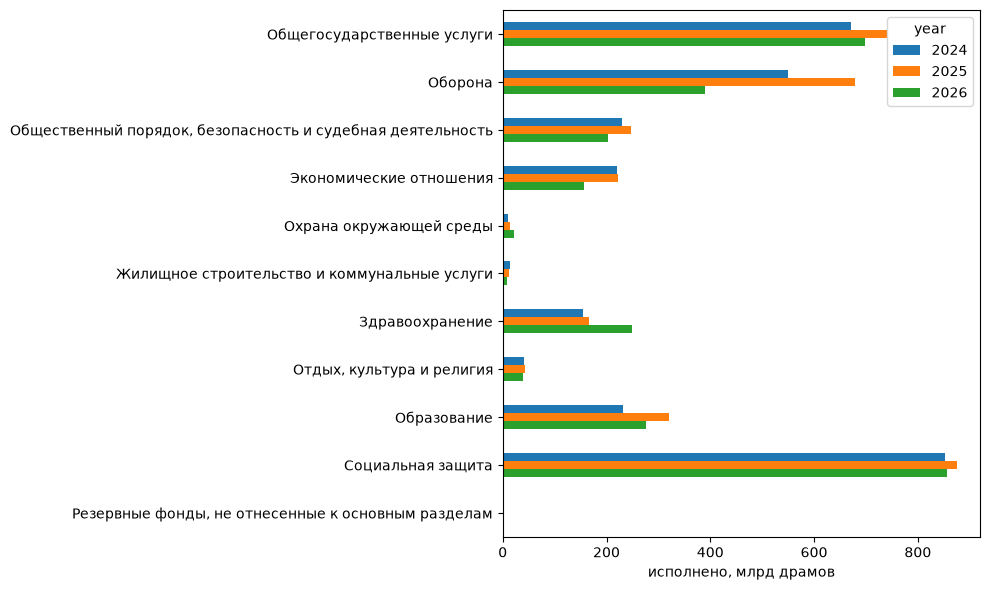

In [3]:
df = q("""
SELECT year, func_section_code, func_section_ru, round(year_actual_kamd / 1e6, 1) AS actual_bn
FROM v_expenditure_by_function ORDER BY func_section_code, year""")
pv = df.pivot_table(index=["func_section_code", "func_section_ru"], columns="year", values="actual_bn").reset_index(level=0, drop=True)
ax = pv.plot.barh(figsize=(10, 6))
ax.set_xlabel("исполнено, млрд драмов")
ax.set_ylabel("")
ax.invert_yaxis()
plt.tight_layout()
pv

## Исполнение по периодам

План и исполнение нарастающим итогом (I квартал, полугодие, 9 месяцев, год) за последний завершённый год.

,sort,period,plan_bn,actual_bn
0,1,I квартал (январь-март),818.1,576.7
1,2,I полугодие (январь-июнь),1726.9,1473.4
2,3,9 месяцев (январь-сентябрь),2571.3,2208.3
3,4,Год,3459.8,3319.1


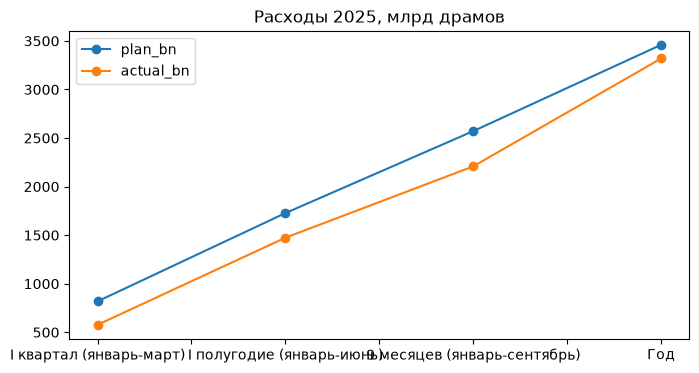

In [4]:
year = q("SELECT max(year) AS y FROM meta_year WHERE is_complete").y[0]
df = q("""
SELECT p.sort, p.label_ru AS period, round(sum(plan_kamd) / 1e6, 1) AS plan_bn, round(sum(actual_kamd) / 1e6, 1) AS actual_bn
FROM v_expenditure_long f JOIN dim_period p USING (period)
WHERE f.year = $year GROUP BY ALL ORDER BY p.sort""", year=int(year))
ax = df.plot(x="period", y=["plan_bn", "actual_bn"], marker="o", figsize=(8, 4), title=f"Расходы {year}, млрд драмов")
ax.set_xlabel("")
df

## Ведомства: план и исполнение

In [5]:
q("""
SELECT department_code, department_ru, round(year_plan_kamd / 1e6, 2) AS plan_bn, round(year_actual_kamd / 1e6, 2) AS actual_bn,
       year_execution_pct
FROM v_expenditure_by_department WHERE year = $year ORDER BY year_plan_kamd DESC LIMIT 15""", year=int(year))

,department_code,department_ru,plan_bn,actual_bn,year_execution_pct
0,104013,Министерство обороны РА,698.44,680.78,97.5
1,105002,Единая социальная служба Министерства труда и социальных вопросов РА,609.11,600.66,98.6
2,105013,Комитет государственных доходов РА,397.80,373.79,94.0
3,104021,Министерство финансов РА,369.04,355.00,96.2
4,104001,Министерство территориального управления и инфраструктур РА,286.83,265.78,92.7
5,104010,"Министерство образования, науки, культуры и спорта РА",185.19,170.64,92.1
6,104002,Министерство здравоохранения РА,167.48,161.69,96.5
7,104027,Министерство внутренних дел РА,108.93,105.92,97.2
8,104004,Министерство экономики РА,76.84,74.68,97.2
9,105018,Служба национальной безопасности РА,57.48,55.56,96.7


## Экономическая классификация

Верхние уровни (класс → категория → группа) взяты из указаний по применению классификации (PDF на сайте).

In [6]:
q("""
SELECT e.category_code, l.name_ru AS category, round(sum(f.year_actual_kamd) / 1e6, 1) AS actual_bn,
       round(100 * sum(f.year_actual_kamd) / sum(sum(f.year_actual_kamd)) OVER (), 1) AS share_pct
FROM fact_expenditure f JOIN dim_economic e ON e.code = f.economic_code
LEFT JOIN dim_economic_level l ON l.code = e.category_code
WHERE f.year = $year GROUP BY ALL ORDER BY actual_bn DESC""", year=int(year))

,category_code,category,actual_bn,share_pct
0,47,Социальные пособия и пенсии,1095.2,33.0
1,51,Основные средства,702.7,21.2
2,44,Проценты,349.1,10.5
3,46,Гранты,318.8,9.6
4,48,Прочие расходы,278.5,8.4
5,41,Оплата труда,258.9,7.8
6,45,Субсидии,210.7,6.3
7,42,Приобретение услуг и товаров,105.2,3.2
8,65,NaN,0.0,0.0
9,77,NaN,-0.0,-0.0


## Названия на трёх языках

Крупнейшие программы (мероприятия) текущего года: армянский оригинал и переводы.

In [7]:
q("""
SELECT program_code, any_value(program_hy) AS hy, any_value(program_en) AS en, any_value(program_ru) AS ru,
       round(sum(year_plan_kamd) / 1e6, 1) AS plan_bn
FROM v_expenditure WHERE year = (SELECT max(year) FROM meta_year)
GROUP BY program_code ORDER BY plan_bn DESC LIMIT 10""")

,program_code,hy,en,ru,plan_bn
0,000385,Կառավարության պարտքի սպասարկում (տոկոսավճարներ),Government debt servicing (interest payments),Обслуживание государственного долга (выплата процентов),386.6
1,000973,Աշխատանքային կենսաթոշակներ,Labour pensions,Трудовые пенсии,336.5
2,002439,ՀՀ պաշտպանության նախարարության շենքային պայմանների բարելավում,Improvement of building conditions of the RA Ministry of Defence,Улучшение условий зданий Министерства обороны РА,304.0
3,000046,Ռազմական կարիքների բավարարում,Meeting military needs,Удовлетворение военных потребностей,255.2
4,001546,Կուտակային կենսաթոշակային համակարգի ներդնում,Introduction of the funded pension system,Внедрение накопительной пенсионной системы,244.0
5,004022,Առողջապահության ոլորտի այլ միջոցառումներ,Other measures in the healthcare sector,Прочие мероприятия в сфере здравоохранения,137.1
6,000711,Հանրակրթական ուսուցում,General education,Общее образование,126.1
7,000388,Համայնքների բյուջեներին ֆինանսական համահարթեցման սկզբունքով դոտացիաների տրամ...,Provision of dotations to community budgets on the principle of financial eq...,Предоставление дотаций бюджетам общин по принципу финансового выравнивания и...,107.9
8,004621,Հիպոթեքային վարկի վճարված տոկոսների գումարների վերադարձ,Refund of interest amounts paid on mortgage loans,Возврат сумм уплаченных процентов по ипотечным кредитам,104.6
9,000005,"Գործադիր իշխանության, պետական կառավարման հանրապետական և տարածքային կառավարմա...",Maintenance of republican and territorial public administration bodies of th...,Содержание республиканских и территориальных органов государственного управл...,77.8


## Доходы по видам и разделам

In [8]:
df = q("""
SELECT year, revenue_type_ru, round(sum(year_plan_kamd) / 1e6, 1) AS plan_bn, round(sum(year_actual_kamd) / 1e6, 1) AS actual_bn
FROM v_revenue GROUP BY ALL ORDER BY year, revenue_type_ru""")
df

,year,revenue_type_ru,plan_bn,actual_bn
0,2024,Налоги и пошлины,2579.3,2390.9
1,2024,Официальные гранты,12.2,21.1
2,2024,Прочие доходы,88.0,161.5
3,2025,Налоги и пошлины,2717.6,2717.9
4,2025,Официальные гранты,19.0,4.5
5,2025,Прочие доходы,108.0,150.5
6,2026,Налоги и пошлины,3056.6,2569.4
7,2026,Официальные гранты,38.2,18.5
8,2026,Прочие доходы,109.5,113.3


In [9]:
q("""
SELECT rev_section_code, any_value(rev_section_ru) AS section, round(sum(year_plan_kamd) / 1e6, 1) AS plan_bn,
       round(sum(year_actual_kamd) / 1e6, 1) AS actual_bn
FROM v_revenue WHERE year = $year GROUP BY rev_section_code ORDER BY actual_bn DESC LIMIT 15""", year=int(year))

,rev_section_code,section,plan_bn,actual_bn
0,01,НДС с юридических лиц,0.0,753.7
1,60,Подоходный налог,0.0,724.1
2,05,Налог на прибыль,0.0,400.5
3,61,"НДС, взимаемый налоговыми органами РА с товаров, ввозимых из государств-член...",0.0,155.1
4,59,Социальные платежи,0.0,116.4
5,16,Государственные пошлины,82.3,95.8
6,03,"Акцизный налог на товары, производимые в РА",0.0,89.8
7,58,Налог с оборота,0.0,79.1
8,04,"Акцизный налог на товары, ввозимые в РА",0.0,73.2
9,17,Плата за использование природных ресурсов и охрану окружающей среды,0.0,71.0


## Финансирование дефицита

Складываются только пронумерованные строки (`item_code`); строки `detail` — расшифровки.

In [10]:
q("""
SELECT item_code, row_kind, label_ru, round(year_plan_kamd / 1e6, 1) AS plan_bn, round(year_actual_kamd / 1e6, 1) AS actual_bn
FROM v_deficit WHERE year = $year AND item_code IS NOT NULL ORDER BY line_no""", year=int(year))

,item_code,row_kind,label_ru,plan_bn,actual_bn
0,TOTAL,total,ВСЕГО,409.9,278.9
1,A,source,А. Внутренние источники – всего,265.9,296.7
2,A.1,item,1. Заемные средства,291.4,297.0
3,A.1.1,subitem,1.1 Чистые поступления от выпуска и размещения ценных бумаг,291.4,297.0
4,A.2,item,2. Чистые финансовые активы,-25.5,-0.3
5,A.2.1,subitem,2.1 Поступления от реализации акций и иного участия в капитале,0.0,0.0
6,A.2.2,subitem,2.2 Приобретение акций и иного участия в капитале,-0.3,-0.1
7,A.2.3,subitem,2.3. Свободный остаток средств государственного бюджета РА 2017 года на нача...,14.8,-8.0
8,A.2.4,subitem,2.4 Предоставление кредитов и займов,-64.1,-15.5
9,A.2.5,subitem,2.5 Поступления от возврата предоставленных кредитов и займов,31.9,31.5


## Договоры

Крупнейшие контрагенты по оплатам из бюджета (наименования транслитерированы автоматически).

In [11]:
q("""
SELECT partner_hy, any_value(partner_ru) AS partner_ru, count(*) AS contracts, round(sum(paid_kamd) / 1e3, 1) AS paid_mln_amd
FROM fact_contract WHERE year = $year GROUP BY partner_hy ORDER BY paid_mln_amd DESC LIMIT 15""", year=int(year))

,partner_hy,partner_ru,contracts,paid_mln_amd
0,Գյուղական տարածքների տնտեսական զարգացման ԾԻԳ ՊՀ-ի ԳՖԿ,Гюгакан тарацкнери тнтесакан заргацман ЦИГ ПХ-и ГФК,8,28546.9
1,Վասպուրականի ՃՇՇ,Васпуракани ЧШШ,17,12603.1
2,Էրեբունի Բժշկական Կենտրոն ՓԲԸ,Эребуни Бжшкакан Кентрон ЗАО,9,9147.9
3,Նատալի ֆարմ ՍՊԸ Աստղիկ բժշկական կենտրոն,Натали фарм ООО Астгик бжшкакан кентрон,9,7560.2
4,-Հայաստանի հանրային հեռուստաընկերություն- ՓԲԸ,«Хаястани ханрайин херустаынкерутюн» ЗАО,4,7088.5
5,ԷԿՈ ԲԻԼԴԻՆԳ ՍՊԸ,ЭКО БИЛДИНГ ООО,17,6274.3
6,Մերիդիան Հոլդինգ ՓԲԸ,Меридиан Холдинг ЗАО,1,5775.0
7,Բիդեք ՍՊԸ,Бидек ООО,21,5457.5
8,Արաբկիր Բժշկական Համալիր ԵԴԱԻ ՍՊԸ,Арабкир Бжшкакан Хамалир ЕДАИ ООО,9,4795.0
9,Սուրբ Գրիգոր Լուսավորիչ ԲԿ ՓԲԸ,Сурб Григор Лусаворич БК ЗАО,90,4541.6


In [12]:
q("""
SELECT economic_code, any_value(economic_en) AS article, count(*) AS contracts, round(sum(paid_kamd) / 1e6, 2) AS paid_bn
FROM v_contract WHERE year = $year GROUP BY economic_code ORDER BY paid_bn DESC LIMIT 10""", year=int(year))

,economic_code,article,contracts,paid_bn
0,4729,Other benefits from the budget,1354,108.63
1,5113,Capital repair of buildings and structures,708,89.70
2,5112,Construction of buildings and structures,525,82.56
3,4637,Current grants to state and community non-commercial organisations,330,49.76
4,4522,Subsidies to non-state financial organisations,35,39.04
5,4511,Subsidies to non-financial state organisations,634,33.01
6,4639,Other current grants,3439,32.94
7,4239,Other general services,778,20.26
8,5129,Other machinery and equipment,2401,12.94
9,4251,Current repair and maintenance of buildings and structures,306,10.06


## Проверки качества

In [13]:
q('SELECT * FROM qc_summary ORDER BY check_name')

,check_name,status,n_issues,description
0,balance,info,2,years where expenditure plan - revenue plan <> deficit plan (by more than 0....
1,contract_link,ok,0,contract lines without contracts / contracts without a line
2,contract_paid,info,53,lines where contract payments exceed the executed amount
3,missing_translation,ok,0,names without an en or ru translation
4,renamed_code,info,20,codes whose name changed between years
5,revenue_types,ok,0,years where revenue types do not add up to all revenues
6,revenue_unallocated,info,6,year x revenue type with plan not distributed to accounts
7,site_total,ok,0,start page totals that differ from the database
8,tree_subtotal,ok,0,subtotals that differ from the sum of their children
9,tree_total,ok,0,requests whose fact rows do not add up to the grand total
